# Árvores de decisão para detecção de fadiga em corrida com IMUs

Segundo notebook do projeto. O [01](01_exploracao_inicial.ipynb) mapeou o dataset
4TU ([doi:10.4121/14307743.v1](https://doi.org/10.4121/14307743.v1)) e terminou
com um alerta: a `TableFeats` é **separável demais** para ser tomada ao pé da
letra. Aqui integramos ao projeto o algoritmo de **árvores de decisão** e, ao
longo do caminho, tratamos esse alerta como parte do problema.

**Tarefa:** classificar cada passada em `none` / `mild` / `heavy` (coluna
`fatigue`, 3 classes exatamente balanceadas, acaso = 0,333).

**Roteiro**

1. Dados e escolha das features
2. Como uma árvore decide — o critério de Gini à mão e uma árvore rasa
3. Por que a validação aleatória engana
4. Profundidade, sobreajuste e poda — com validação aninhada
5. Resultado honesto (leave-one-subject-out) e comparação com floresta aleatória
6. Que features a árvore usa — e se ela é estável
7. Sensibilidade: `HR_norm` e o sujeito `p001`
8. Conclusões e limitações

In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             confusion_matrix, f1_score)
from sklearn.model_selection import (GridSearchCV, GroupKFold, LeaveOneGroupOut,
                                     cross_val_predict, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Mesma convenção do notebook 01: trabalhar a partir da raiz do projeto.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import src

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.max_columns", 60)

SEED = 0
CLASSES = {0: "none", 1: "mild", 2: "heavy"}
PALETA = {"none": "#4C9F70", "mild": "#E0A458", "heavy": "#C1666B"}

## 1. Dados e escolha das features

Lemos a `TableFeats` já exportada (12.513 passadas × 165 colunas). Das 165, só
157 são features do artigo; as demais são rótulo ou contexto. Cada decisão
abaixo tem um motivo:

| coluna(s) | decisão | motivo |
|---|---|---|
| `fatigue` | alvo | é o que queremos prever |
| `rpe` | **fora** | é o *desfecho* (esforço percebido reportado), não um sinal medido; usá-lo seria vazar o rótulo |
| `sub` | **fora das features**, usado como **grupo** de validação | identificar o corredor não é fadiga; e é a unidade correta para separar treino de teste |
| `experience`, `weight`, `height`, `speed` | **fora** | constantes por sujeito: a árvore as usaria como "carteira de identidade" do corredor |
| `HR_norm` | testada à parte (seção 7) | única coluna com ausentes — todas as linhas de `p001` |

In [2]:
feats = pd.read_csv(src.PREPROCESSED / "TableFeats.csv")

ALVO, GRUPO = "fatigue", "sub"
FORA = ["rpe", "sub", "experience", "weight", "height", "speed", "fatigue"]
FEATURES = [c for c in feats.columns if c not in FORA]            # 158, com HR_norm
FEATURES_SEM_HR = [c for c in FEATURES if c != "HR_norm"]          # 157

y = feats[ALVO].to_numpy()
g = feats[GRUPO].to_numpy()

print(f"{len(feats):,} passadas · {len(FEATURES)} features (157 + HR_norm) · {len(np.unique(g))} sujeitos")
print("linhas sem HR_norm:", int(feats['HR_norm'].isna().sum()), "→ sujeito(s)", [int(s_) for s_ in sorted(feats.loc[feats['HR_norm'].isna(), 'sub'].unique())])

12,513 passadas · 158 features (157 + HR_norm) · 8 sujeitos
linhas sem HR_norm: 1296 → sujeito(s) [1]


Um detalhe prático: árvores do scikit-learn aceitam `NaN` só a partir da 1.3 e
depende do critério; para não depender disso, todo modelo abaixo é um
`Pipeline` com `SimpleImputer(median)`. Estar **dentro** do pipeline importa — a
mediana é recalculada só com o treino de cada dobra, sem espiar o teste.

## 2. Como uma árvore decide

Uma árvore de decisão particiona o espaço de features com perguntas do tipo
`feature ≤ limiar?`. Em cada nó ela escolhe a pergunta que mais reduz a
**impureza de Gini**:

$$G = 1-\sum_k p_k^2 \qquad\qquad \Delta = G_{pai} - \Big(\tfrac{n_E}{n}G_E + \tfrac{n_D}{n}G_D\Big)$$

($G=0$: nó puro; $G=2/3$: três classes igualmente misturadas.) Para ver que não
há mágica, fazemos a busca do melhor corte da raiz **à mão** sobre todas as
features e comparamos com o que o scikit-learn escolhe.

In [3]:
def gini(y_):
    p = np.bincount(y_, minlength=3) / len(y_)
    return 1 - np.sum(p ** 2)


def melhor_corte(x, y_):
    # Varre todos os limiares (pontos médios entre valores consecutivos). Só NaN-safe porque
    # aqui filtramos os ausentes; a versão do sklearn faz o mesmo com ordenação incremental.
    ok = ~np.isnan(x)
    x, y_ = x[ok], y_[ok]
    ordem = np.argsort(x)
    x, y_ = x[ordem], y_[ordem]
    n, G_pai = len(y_), gini(y_)
    esq = np.zeros(3)
    dir_ = np.bincount(y_, minlength=3).astype(float)
    melhor = (0.0, None)
    for i in range(n - 1):
        esq[y_[i]] += 1
        dir_[y_[i]] -= 1
        if x[i] == x[i + 1]:
            continue
        nE, nD = i + 1, n - i - 1
        gE = 1 - np.sum((esq / nE) ** 2)
        gD = 1 - np.sum((dir_ / nD) ** 2)
        ganho = G_pai - (nE * gE + nD * gD) / n
        if ganho > melhor[0]:
            melhor = (ganho, (x[i] + x[i + 1]) / 2)
    return melhor


print(f"Gini da raiz (3 classes balanceadas): {gini(y):.4f}  (= 2/3)")
ganhos = {f: melhor_corte(feats[f].to_numpy(), y) for f in FEATURES_SEM_HR}
raiz_manual = (pd.DataFrame(ganhos, index=["ganho", "limiar"]).T
               .sort_values("ganho", ascending=False))
raiz_manual.head(8)

Gini da raiz (3 classes balanceadas): 0.6667  (= 2/3)


,ganho,limiar
MS_max_3,0.323000,-0.407012
sla,0.270390,-0.353748
meanlk,0.264351,-0.256283
MS_max_1,0.263593,-0.126174
sdlllav,0.253450,0.615283
sdlll,0.252749,-0.700418
srh,0.248264,-0.312519
meanrk,0.248132,-0.374316


In [4]:
arv_demo = make_pipeline(SimpleImputer(strategy="median"),
                         DecisionTreeClassifier(max_depth=1, random_state=SEED))
arv_demo.fit(feats[FEATURES_SEM_HR], y)
t = arv_demo[-1].tree_
print("sklearn  → raiz:", FEATURES_SEM_HR[t.feature[0]], "≤", round(t.threshold[0], 4))
print("à mão    → raiz:", raiz_manual.index[0], "≤", round(raiz_manual.iloc[0, 1], 4))

sklearn  → raiz: MS_max_3 ≤ -0.407
à mão    → raiz: MS_max_3 ≤ -0.407


Bate. Agora uma árvore rasa (profundidade 3) ajustada em todos os dados — **só
para ler**, não para avaliar. É a grande vantagem do método: o modelo inteiro
cabe numa figura e numa regra em texto.

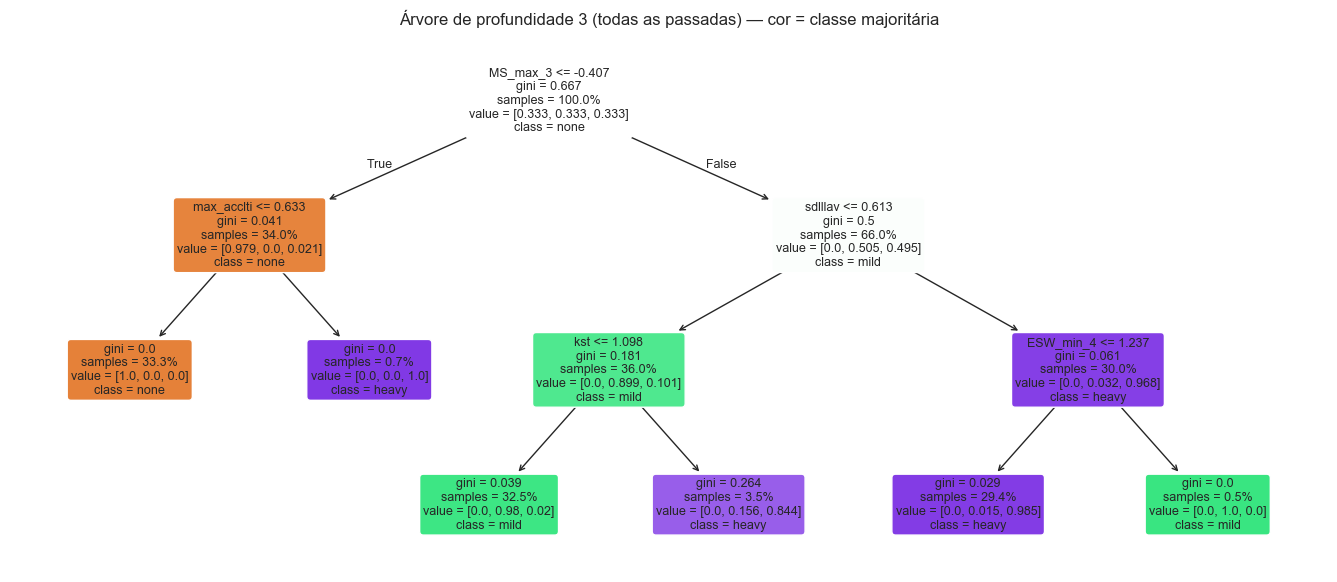

In [5]:
arv_leitura = DecisionTreeClassifier(max_depth=3, random_state=SEED)
arv_leitura.fit(feats[FEATURES_SEM_HR], y)

fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(arv_leitura, feature_names=FEATURES_SEM_HR,
          class_names=list(CLASSES.values()), filled=True, rounded=True,
          impurity=True, proportion=True, fontsize=9, ax=ax)
ax.set_title("Árvore de profundidade 3 (todas as passadas) — cor = classe majoritária")
plt.show()

In [6]:
print(export_text(arv_leitura, feature_names=FEATURES_SEM_HR, decimals=2))

|--- MS_max_3 <= -0.41
|   |--- max_acclti <= 0.63
|   |   |--- class: 0
|   |--- max_acclti >  0.63
|   |   |--- class: 2
|--- MS_max_3 >  -0.41
|   |--- sdlllav <= 0.61
|   |   |--- kst <= 1.10
|   |   |   |--- class: 1
|   |   |--- kst >  1.10
|   |   |   |--- class: 2
|   |--- sdlllav >  0.61
|   |   |--- ESW_min_4 <= 1.24
|   |   |   |--- class: 2
|   |   |--- ESW_min_4 >  1.24
|   |   |   |--- class: 1



Lembrete do notebook 01: as features estão **z-scoradas por sujeito**, então um
limiar como `sla ≤ −0,3` significa "abaixo de 0,3 desvio-padrão *do próprio
corredor*". A regra é interpretável, mas só em escala individual.

## 3. Por que a validação aleatória engana

O reflexo é um `train_test_split` estratificado. Vejamos o que ele diz — e o que
acontece quando o teste é **um corredor que o modelo nunca viu**
(*leave-one-subject-out*, LOSO).

In [7]:
X = feats[FEATURES_SEM_HR]
pipe = lambda **kw: make_pipeline(SimpleImputer(strategy="median"),
                                  DecisionTreeClassifier(random_state=SEED, **kw))

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
acc_aleatorio = pipe().fit(Xtr, ytr).score(Xte, yte)

logo = LeaveOneGroupOut()
pred_loso = cross_val_predict(pipe(), X, y, groups=g, cv=logo)
acc_loso = accuracy_score(y, pred_loso)

print(f"split aleatório 80/20 (árvore sem limite): acurácia = {acc_aleatorio:.3f}")
print(f"LOSO               (árvore sem limite)  : acurácia = {acc_loso:.3f}")

split aleatório 80/20 (árvore sem limite): acurácia = 1.000
LOSO               (árvore sem limite)  : acurácia = 0.739


**≈ 1,00 contra ≈ 0,74** — a mesma árvore, o mesmo dado. Passadas consecutivas
do mesmo corredor, na mesma volta, tendem a ser muito parecidas entre si
(explicação provável; não a testamos aqui). Num split aleatório, cada passada
de teste tem "gêmeas" no treino, e a árvore apenas as memoriza. O número de
≈ 1,000 não mede detecção de fadiga: mede **memorização de vizinhança**.

A unidade de generalização relevante é o **corredor**; por isso, daqui em diante
toda avaliação é feita por sujeito (LOSO, 8 dobras).

## 4. Profundidade, sobreajuste e poda

Uma árvore sem limite cresce até cada folha ficar pura — baixo viés, variância
enorme. Os controles clássicos são `max_depth`, `min_samples_leaf` e a poda por
complexidade de custo (`ccp_alpha`). Primeiro a curva treino × teste (LOSO) em
função da profundidade:

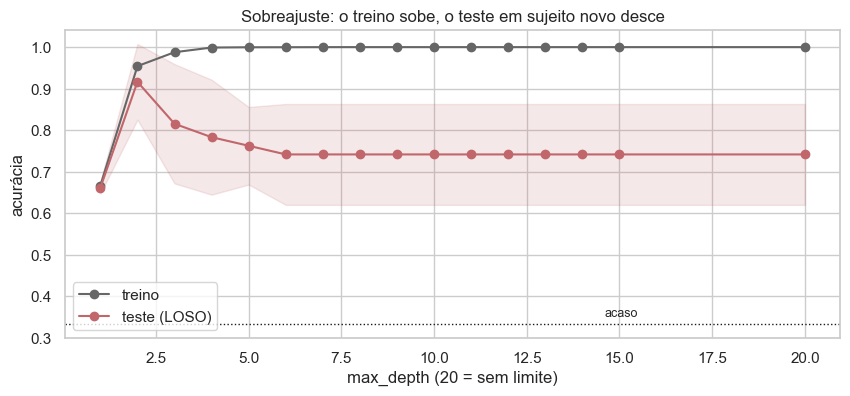

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,20
treino,0.667,0.954,0.988,0.999,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
teste (LOSO),0.661,0.916,0.815,0.783,0.762,0.742,0.742,0.742,0.742,0.742,0.742,0.742,0.742,0.742,0.742,0.742
dp teste,0.014,0.091,0.144,0.138,0.093,0.121,0.121,0.121,0.121,0.121,0.121,0.121,0.121,0.121,0.121,0.121


In [8]:
from sklearn.model_selection import cross_validate

profundidades = list(range(1, 16)) + [None]
linhas = []
for d in profundidades:
    r = cross_validate(pipe(max_depth=d), X, y, groups=g, cv=logo,
                       scoring="accuracy", return_train_score=True)
    linhas.append({"max_depth": d if d else 20,   # 20 = "sem limite" só para o eixo
                   "treino": r["train_score"].mean(),
                   "teste (LOSO)": r["test_score"].mean(),
                   "dp teste": r["test_score"].std()})
curva = pd.DataFrame(linhas).set_index("max_depth")

fig, ax = plt.subplots()
ax.plot(curva.index, curva["treino"], "o-", label="treino", color="0.4")
ax.plot(curva.index, curva["teste (LOSO)"], "o-", label="teste (LOSO)", color="#C1666B")
ax.fill_between(curva.index, curva["teste (LOSO)"] - curva["dp teste"],
                curva["teste (LOSO)"] + curva["dp teste"], color="#C1666B", alpha=.15)
ax.axhline(1/3, ls=":", color="k", lw=1); ax.text(15.5, .35, "acaso", ha="right", fontsize=9)
ax.set(xlabel="max_depth (20 = sem limite)", ylabel="acurácia",
       title="Sobreajuste: o treino sobe, o teste em sujeito novo desce")
ax.legend(); plt.show()
curva.round(3).T

O padrão é o de livro-texto: o treino vai a 1,00 enquanto o teste em sujeito
novo atinge o pico em **profundidade 2 (≈ 0,92)** e cai até ≈ 0,74 (a árvore
satura em ~6 níveis). Árvores fundas aprendem idiossincrasias de 7 corredores,
não a fadiga. Note o desvio-padrão entre dobras (≈ 0,09–0,14): com 8 sujeitos,
diferenças de poucos pontos não são significativas.

Escolher o melhor ponto dessa curva e reportar o *mesmo* número seria
otimista (selecionamos no conjunto de teste). Para um resultado honesto usamos
**validação aninhada**: em cada dobra LOSO externa, o `GridSearchCV` escolhe os
hiperparâmetros só com os 7 sujeitos de treino (`GroupKFold` interno por
sujeito), e o sujeito de fora só é tocado no final.

In [9]:
grade = {
    "decisiontreeclassifier__max_depth": [1, 2, 3, 4, 5, 8, None],
    "decisiontreeclassifier__min_samples_leaf": [1, 20, 60],
    "decisiontreeclassifier__ccp_alpha": [0.0, 0.002, 0.01],
}

pred_aninhado = np.empty_like(y)
escolhas = []
for treino, teste in logo.split(X, y, g):
    busca = GridSearchCV(pipe(), grade, cv=GroupKFold(n_splits=7),
                         scoring="f1_macro", n_jobs=-1)
    busca.fit(X.iloc[treino], y[treino], groups=g[treino])
    pred_aninhado[teste] = busca.predict(X.iloc[teste])
    escolhas.append({"sujeito_teste": g[teste][0],
                     **{k.split("__")[1]: v for k, v in busca.best_params_.items()}})

escolhas = pd.DataFrame(escolhas).set_index("sujeito_teste")
escolhas

/Users/lucasedmundo/miniconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,ccp_alpha,max_depth,min_samples_leaf
sujeito_teste,,,
1,0.0,2,20
5,0.0,2,1
6,0.0,2,20
13,0.0,2,1
15,0.0,4,1
16,0.0,2,1
17,0.0,2,1
18,0.0,8,1


In [10]:
print(f"árvore, validação aninhada: acurácia {accuracy_score(y, pred_aninhado):.3f} · "
      f"F1-macro {f1_score(y, pred_aninhado, average='macro'):.3f}")
print("\nhiperparâmetros escolhidos (nº de dobras externas):")
for col in escolhas:
    print(f"  {col:17}", escolhas[col].astype(str).value_counts().to_dict())

árvore, validação aninhada: acurácia 0.900 · F1-macro 0.901

hiperparâmetros escolhidos (nº de dobras externas):
  ccp_alpha         {'0.0': 8}
  max_depth         {'2': 6, '4': 1, '8': 1}
  min_samples_leaf  {'1': 6, '20': 2}


A busca é **estável entre dobras**: `max_depth=2` em 6 de 8, e `ccp_alpha=0` em
todas — a poda por complexidade não foi escolhida; o que regulariza aqui é a
profundidade. A acurácia aninhada (≈ 0,90) é só um pouco menor que a da
profundidade 2 fixa (≈ 0,92, escolhida olhando a curva acima e portanto um pouco
otimista); o número aninhado é o que deve ser reportado.

## 5. Resultado honesto e comparação com floresta aleatória

Comparamos com (a) um baseline que ignora as features e (b) uma floresta
aleatória — o "irmão" conjunto da árvore, que reduz a variância tirando a média
de muitas árvores. A floresta usa 300 árvores e as mesmas dobras LOSO.

In [11]:
modelos = {
    "acaso (classe mais frequente)": make_pipeline(SimpleImputer(strategy="median"),
                                                   DummyClassifier(strategy="most_frequent")),
    "árvore (aninhada)": None,                      # já calculada acima
    "árvore, profundidade 2": pipe(max_depth=2),
    "floresta aleatória (300)": make_pipeline(SimpleImputer(strategy="median"),
                                              RandomForestClassifier(300, random_state=SEED, n_jobs=-1)),
}
PREDS = {}
for nome, m in modelos.items():
    PREDS[nome] = pred_aninhado if m is None else cross_val_predict(m, X, y, groups=g, cv=logo)

resultado = pd.DataFrame({
    nome: {"acurácia": accuracy_score(y, p), "F1-macro": f1_score(y, p, average="macro"),
           "erros none↔heavy": int(((y == 0) & (p == 2)).sum() + ((y == 2) & (p == 0)).sum())}
    for nome, p in PREDS.items()}).T
resultado.round(3)

,acurácia,F1-macro,erros none↔heavy
acaso (classe mais frequente),0.333,0.167,4171.0
árvore (aninhada),0.900,0.901,336.0
"árvore, profundidade 2",0.917,0.917,336.0
floresta aleatória (300),0.872,0.873,35.0


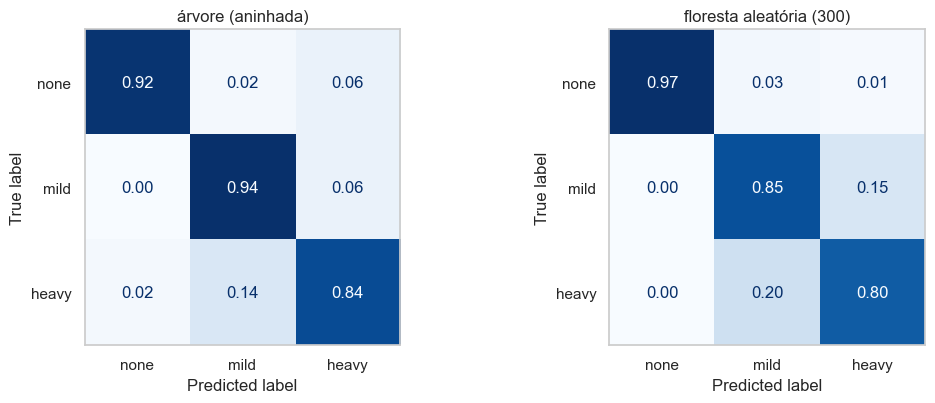

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, nome in zip(axes, ["árvore (aninhada)", "floresta aleatória (300)"]):
    ConfusionMatrixDisplay(confusion_matrix(y, PREDS[nome], normalize="true"),
                           display_labels=list(CLASSES.values())).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".2f")
    ax.set_title(nome); ax.grid(False)
plt.tight_layout(); plt.show()

Surpresa: **a árvore rasa supera a floresta** (0,90–0,92 contra 0,87). Os erros
`none↔heavy` são raros nos dois (336 e 35 de 12.513), mas bem mais raros na
floresta — ela erra "para o lado". Por sujeito, a floresta vai muito mal em
`sub=6` (0,70) e a árvore em `sub=15` (≈ 0,67–0,71); a árvore depende de poucas
features (limiares que funcionam para uns corredores e não para outros), a
floresta dilui isso, mas aqui perde. Com 8 sujeitos, não dá para afirmar que a
diferença é geral. Por sujeito:

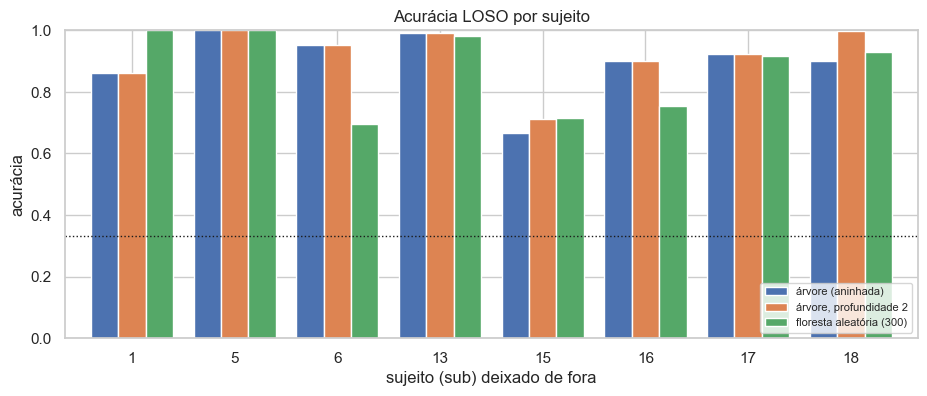

,árvore (aninhada),"árvore, profundidade 2",floresta aleatória (300),n_passadas
1,0.860,0.860,1.000,1296
5,1.000,1.000,1.000,1683
6,0.951,0.951,0.695,1641
13,0.991,0.991,0.981,1761
15,0.665,0.710,0.716,1677
16,0.899,0.899,0.752,1410
17,0.923,0.923,0.917,1641
18,0.900,0.997,0.929,1404


In [13]:
por_sujeito = pd.DataFrame({
    nome: pd.Series(p == y).groupby(g).mean()
    for nome, p in PREDS.items() if not nome.startswith("acaso")})
por_sujeito["n_passadas"] = pd.Series(g).value_counts().sort_index()

ax = por_sujeito.drop(columns="n_passadas").plot.bar(figsize=(11, 4), width=.8)
ax.axhline(1/3, ls=":", color="k", lw=1)
ax.set(xlabel="sujeito (sub) deixado de fora", ylabel="acurácia", ylim=(0, 1),
       title="Acurácia LOSO por sujeito")
ax.legend(loc="lower right", fontsize=8); plt.xticks(rotation=0); plt.show()
por_sujeito.round(3)

## 6. Que features a árvore usa — e se ela é estável

A importância por impureza (MDI) soma o ganho de Gini de cada feature. É barata
mas tende a favorecer features contínuas e correlacionadas — e já vimos no
notebook 01 que há muita redundância. Por isso conferimos de duas formas:
**(a)** MDI numa floresta; **(b)** com que frequência cada feature é a **raiz**
da árvore quando retiramos cada sujeito (estabilidade).

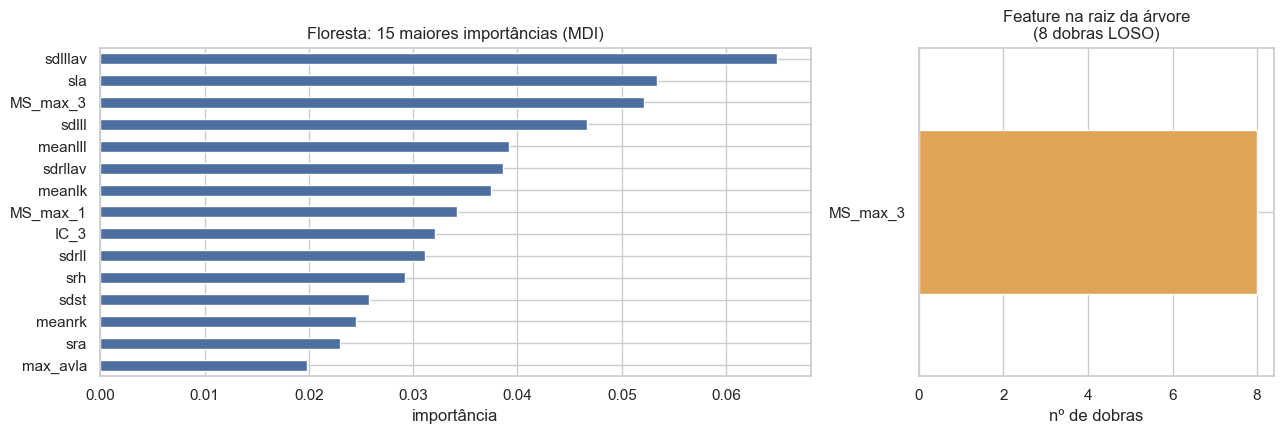

In [14]:
floresta = make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(300, random_state=SEED, n_jobs=-1)).fit(X, y)
imp = pd.Series(floresta[-1].feature_importances_, index=FEATURES_SEM_HR).sort_values(ascending=False)

raizes = []
for treino, _ in logo.split(X, y, g):
    a = pipe().fit(X.iloc[treino], y[treino])[-1]
    raizes.append(FEATURES_SEM_HR[a.tree_.feature[0]])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
imp.head(15)[::-1].plot.barh(ax=axes[0], color="#4C6F9F")
axes[0].set(title="Floresta: 15 maiores importâncias (MDI)", xlabel="importância")
pd.Series(raizes).value_counts()[::-1].plot.barh(ax=axes[1], color="#E0A458")
axes[1].set(title="Feature na raiz da árvore\n(8 dobras LOSO)", xlabel="nº de dobras")
plt.tight_layout(); plt.show()

In [15]:
print("raízes encontradas:", sorted(set(raizes)))
print("top-5 da floresta :", list(imp.index[:5]))

raízes encontradas: ['MS_max_3']
top-5 da floresta : ['sdlllav', 'sla', 'MS_max_3', 'sdlll', 'meanlll']


A **raiz é `MS_max_3` em todas as 8 dobras** — a regra principal é estável.
Pelo esquema de nomes do notebook 01 (seção 2.4), `MS_max_3` é o pico de
velocidade angular no joelho esquerdo (swing); `sdlllav` é a variabilidade da
velocidade angular da tíbia esquerda; `sla` é a assimetria (skewness) do ângulo
do tornozelo esquerdo. Ou seja, o sinal útil vem do **membro inferior
esquerdo** — vale checar se é característica do dataset ou coincidência de
features redundantes (o notebook 01 mostrou muita colinearidade; MDI divide
crédito entre correlacionadas).

## 7. Sensibilidade: `HR_norm` e o sujeito `p001`

`HR_norm` (frequência cardíaca normalizada) é a feature mais correlacionada com o
rótulo (ρ ≈ 0,94 no notebook 01) mas **não existe para `p001`**. Comparamos a
árvore rasa com e sem ela. Sem `HR_norm`, `p001` participa normalmente; com ela,
sua coluna é imputada pela mediana do treino (um valor sem informação), o que
penaliza o sujeito exatamente onde a árvore mais se apoia na feature.

In [16]:
linhas = []
for nome, cols in [("sem HR_norm (157)", FEATURES_SEM_HR), ("com HR_norm (158)", FEATURES)]:
    for d in (2, 3, 5):
        p = cross_val_predict(pipe(max_depth=d), feats[cols], y, groups=g, cv=logo)
        acc_suj = pd.Series(p == y).groupby(g).mean()
        linhas.append({"features": nome, "max_depth": d,
                       "acurácia": accuracy_score(y, p),
                       "F1-macro": f1_score(y, p, average="macro"),
                       "acurácia p001 (sub=1)": acc_suj[1],
                       "acurácia sem p001": pd.Series(p == y)[g != 1].mean()})
pd.DataFrame(linhas).round(3)

,features,max_depth,acurácia,F1-macro,acurácia p001 (sub=1),acurácia sem p001
0,sem HR_norm (157),2,0.917,0.917,0.860,0.924
1,sem HR_norm (157),3,0.814,0.816,0.891,0.805
2,sem HR_norm (157),5,0.761,0.764,0.719,0.766
3,com HR_norm (158),2,0.870,0.870,0.667,0.893
4,com HR_norm (158),3,0.770,0.774,0.642,0.785
5,com HR_norm (158),5,0.751,0.755,0.642,0.764


Duas leituras: (i) incluir `HR_norm` **piora** a árvore em todas as
profundidades testadas — inclusive para os 7 sujeitos que a possuem
(`acurácia sem p001`: 0,924 → 0,893 na profundidade 2); e (ii) em `p001`, a
queda é grande (0,86 → 0,67), pois imputar uma coluna *inteira* ausente injeta
um valor sem informação justo onde a árvore se apoia. A recomendação é
manter o modelo **sem `HR_norm`**: ele cobre os 8 sujeitos e não depende de um
sensor extra (cinta cardíaca), o que também é mais coerente com o objetivo de
detecção apenas por IMU.

## 8. Conclusões e limitações

**O que fizemos:** integramos árvores de decisão ao projeto de ponta a ponta —
critério de Gini verificado à mão, árvore interpretável, diagnóstico de
sobreajuste, poda e escolha de hiperparâmetros por validação aninhada em
sujeito, comparação com floresta aleatória e análise de estabilidade das
features.

**O que aprendemos**

- **A forma de validar importa mais que o algoritmo.** O mesmo modelo vai de
  ≈ 1,00 (split aleatório) a ≈ 0,74–0,92 (LOSO, conforme a profundidade). Nada do que segue deve ser lido
  fora do protocolo por sujeito.
- **Árvores fundas sobreajustam em sujeito novo**; a profundidade 2 (uma
  regra de 3–4 folhas, raiz sempre `MS_max_3`) generalizou melhor: ≈ 0,90 aninhado.
- **Aqui a árvore rasa bateu a floresta** (0,90–0,92 vs 0,87), embora a floresta
  cometa muito menos erros extremos `none↔heavy`. Diferença não conclusiva com 8 sujeitos.
- `HR_norm` piora o modelo e foi descartada.
- Erros concentram-se em classes **adjacentes**, como esperado de um processo
  gradual.

**Limitações (herdadas do notebook 01 e que continuam valendo)**

1. **A normalização por sujeito é transdutiva.** As features já vieram
   z-scoradas usando a distribuição do próprio sujeito *nas três condições*;
   portanto o LOSO acima mede "detectar fadiga num corredor cuja linha de base
   foi calibrada", não num corredor completamente novo. Os números aqui são
   melhores que os ≈ 0,69 do baseline por janelas do `NOTES.md` justamente por
   isso — comparar os dois sem essa ressalva seria enganoso.
2. **Passadas não são independentes** (mesma volta, mesmo corredor); só 8
   sujeitos — a incerteza real é grande, e o desvio entre dobras (seção 4) não
   a captura inteira.
3. **`p007`** contribui só 2 das 3 classes nas gravações brutas; na `TableFeats`
   ele aparece nas três, mas vale reportá-lo separadamente se o trabalho
   avançar para o sinal bruto.
4. Os limiares das árvores estão em unidades z-score por sujeito — não são
   diretamente aplicáveis a um relógio/sensor novo sem uma etapa de calibração.

**Próximos passos:** (a) repetir a comparação com features por janela do sinal
bruto *sem* normalização transdutiva (normalizando só com a linha de base
`none` do próprio sujeito ou com estatísticas do treino); (b) *gradient
boosting* (`HistGradientBoostingClassifier`) como próxima família de árvores;
(c) tratar o problema como ordinal (`none < mild < heavy`), já que os erros são
adjacentes.